# **Loading the data**

---



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('/content/Pakistani_Diabetes_Dataset.csv')
data = data.reset_index(drop=True)
data.head()

,Age,Gender,Rgn,wt,BMI,wst,sys,dia,his,A1c,B.S.R,vision,Exr,dipsia,uria,Dur,neph,HDL,Outcome
0,60.0,1,0,76.0,29.90,41.0,130,90,0,8.90,278,0,30,1,0,5.0,0,60,1
1,57.0,1,1,64.0,24.30,39.0,120,80,1,8.50,165,0,20,1,1,20.0,0,42,1
2,58.0,0,0,73.0,25.20,34.0,140,90,0,5.65,130,1,20,0,0,0.0,0,54,0
3,27.0,0,1,60.0,22.01,30.0,110,70,0,5.00,95,0,15,0,0,0.0,0,57,0
4,56.0,1,0,70.0,25.80,43.0,125,90,0,8.30,139,1,40,1,0,5.0,1,53,1


In [ ]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 19 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Age      912 non-null    float64
 1   Gender   912 non-null    int64  
 2   Rgn      912 non-null    int64  
 3   wt       912 non-null    float64
 4   BMI      912 non-null    float64
 5   wst      912 non-null    float64
 6   sys      912 non-null    int64  
 7   dia      912 non-null    int64  
 8   his      912 non-null    int64  
 9   A1c      912 non-null    float64
 10  B.S.R    912 non-null    int64  
 11  vision   912 non-null    int64  
 12  Exr      912 non-null    int64  
 13  dipsia   912 non-null    int64  
 14  uria     912 non-null    int64  
 15  Dur      912 non-null    float64
 16  neph     912 non-null    int64  
 17  HDL      912 non-null    int64  
 18  Outcome  912 non-null    int64  
dtypes: float64(6), int64(13)
memory usage: 135.5 KB


In [ ]:
data.shape

(912, 19)

In [ ]:
%matplotlib inline

# **Class Imbalance**

---



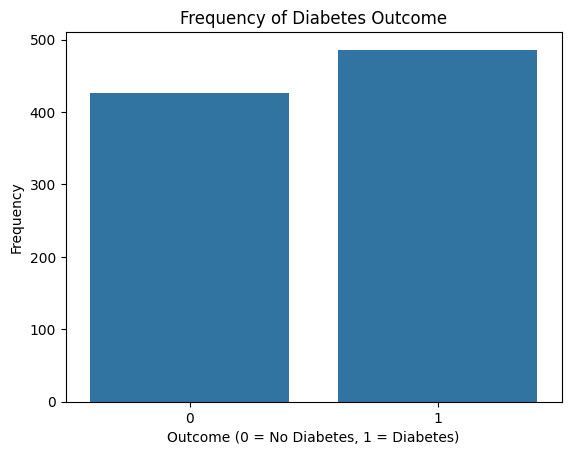

In [ ]:
sns.countplot(x='Outcome', data = data)

plt.title('Frequency of Diabetes Outcome')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Frequency')

plt.show()

In [ ]:
neg = data[data['Outcome'] == 0]
pos = data[data['Outcome'] == 1]

print(len(neg))
print(len(pos))

426
486


In [ ]:
pos = pos.iloc[:len(neg),:]

In [ ]:
print(len(pos))

426


In [ ]:
data = pd.concat((pos, neg), axis = 0)

In [ ]:
print(len(data))

852


# **Data Preprocessing**

---



In [ ]:
data.rename(columns={
    'wt': 'weight_kg',
    'bmi': 'body_mass_index',
    'waist': 'waist_inches',
    'systolic': 'systolic_bp',
    'diastolic': 'diastolic_bp',
    'hba1c': 'hemoglobina1c',
    'bld_sugar': 'blood_sugar_random',
    'exerc': 'exercise_minutes'}, inplace=True)
data.head()

,Age,Gender,Rgn,weight_kg,BMI,wst,sys,dia,his,A1c,B.S.R,vision,Exr,dipsia,uria,Dur,neph,HDL,Outcome
0,60.0,1,0,76.0,29.9,41.0,130,90,0,8.90,278,0,30,1,0,5.0,0,60,1
1,57.0,1,1,64.0,24.3,39.0,120,80,1,8.50,165,0,20,1,1,20.0,0,42,1
4,56.0,1,0,70.0,25.8,43.0,125,90,0,8.30,139,1,40,1,0,5.0,1,53,1
5,45.0,1,1,79.0,30.2,39.0,125,85,1,9.30,238,1,10,1,1,10.0,0,59,1
6,50.0,1,0,74.0,28.0,38.0,150,90,0,8.45,374,1,20,1,1,4.0,0,53,1


# **Info Check**

---



In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 852 entries, 0 to 911
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        852 non-null    float64
 1   Gender     852 non-null    int64  
 2   Rgn        852 non-null    int64  
 3   weight_kg  852 non-null    float64
 4   BMI        852 non-null    float64
 5   wst        852 non-null    float64
 6   sys        852 non-null    int64  
 7   dia        852 non-null    int64  
 8   his        852 non-null    int64  
 9   A1c        852 non-null    float64
 10  B.S.R      852 non-null    int64  
 11  vision     852 non-null    int64  
 12  Exr        852 non-null    int64  
 13  dipsia     852 non-null    int64  
 14  uria       852 non-null    int64  
 15  Dur        852 non-null    float64
 16  neph       852 non-null    int64  
 17  HDL        852 non-null    int64  
 18  Outcome    852 non-null    int64  
dtypes: float64(6), int64(13)
memory usage: 133.1 KB


# **Data Description**

---



In [ ]:
data.describe()

,Age,Gender,Rgn,weight_kg,BMI,wst,sys,dia,his,A1c,B.S.R,vision,Exr,dipsia,uria,Dur,neph,HDL,Outcome
count,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000,852.000000
mean,35.796362,0.535211,0.285211,69.086972,25.491674,35.322183,130.357981,82.328638,0.578638,6.745364,161.495305,0.487089,14.876761,0.356808,0.305164,2.000000,0.160798,46.174883,0.500000
std,13.688576,0.499052,0.451780,12.225835,8.478992,3.943986,19.890057,11.750840,0.494067,2.175367,84.223285,0.500127,15.606127,0.479339,0.460747,2.970057,0.367560,6.764890,0.500294
min,12.000000,0.000000,0.000000,30.000000,2.840000,24.000000,90.000000,20.000000,0.000000,0.100000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,30.000000,0.000000
25%,22.000000,0.000000,0.000000,60.000000,22.320000,32.000000,120.000000,74.000000,0.000000,5.000000,95.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,41.000000,0.000000
50%,35.000000,1.000000,0.000000,69.000000,25.035000,35.000000,127.000000,80.000000,1.000000,5.800000,125.000000,0.000000,15.000000,0.000000,0.000000,0.000000,0.000000,46.000000,0.500000
75%,48.000000,1.000000,1.000000,77.000000,28.220000,38.000000,140.000000,90.000000,1.000000,8.400000,209.000000,1.000000,25.000000,1.000000,1.000000,3.000000,0.000000,52.000000,1.000000
max,70.000000,1.000000,1.000000,110.000000,233.790000,67.000000,245.000000,115.000000,1.000000,14.000000,464.000000,1.000000,120.000000,1.000000,1.000000,25.000000,1.000000,62.000000,1.000000


# **Check for Null**

---



In [ ]:
data.isnull().sum()

,0
Age,0
Gender,0
Rgn,0
weight_kg,0
BMI,0
wst,0
sys,0
dia,0
his,0
A1c,0


# **Unique Values**

---



In [ ]:
data.nunique()

,0
Age,54
Gender,2
Rgn,2
weight_kg,69
BMI,363
wst,91
sys,76
dia,44
his,2
A1c,106


# **Check for Duplicates**

---



In [ ]:
data.duplicated().sum()

np.int64(2)

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
print(len(data))

850


In [ ]:
data.reset_index(drop=True, inplace=True)

# **Histogram**

---



array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Gender'}>,
        <Axes: title={'center': 'Rgn '}>,
        <Axes: title={'center': 'weight_kg'}>],
       [<Axes: title={'center': 'BMI'}>, <Axes: title={'center': 'wst'}>,
        <Axes: title={'center': 'sys'}>, <Axes: title={'center': 'dia'}>],
       [<Axes: title={'center': 'his'}>, <Axes: title={'center': 'A1c'}>,
        <Axes: title={'center': 'B.S.R'}>,
        <Axes: title={'center': 'vision'}>],
       [<Axes: title={'center': 'Exr'}>,
        <Axes: title={'center': 'dipsia'}>,
        <Axes: title={'center': 'uria'}>,
        <Axes: title={'center': 'Dur'}>],
       [<Axes: title={'center': 'neph'}>,
        <Axes: title={'center': 'HDL'}>,
        <Axes: title={'center': 'Outcome'}>, <Axes: >]], dtype=object)

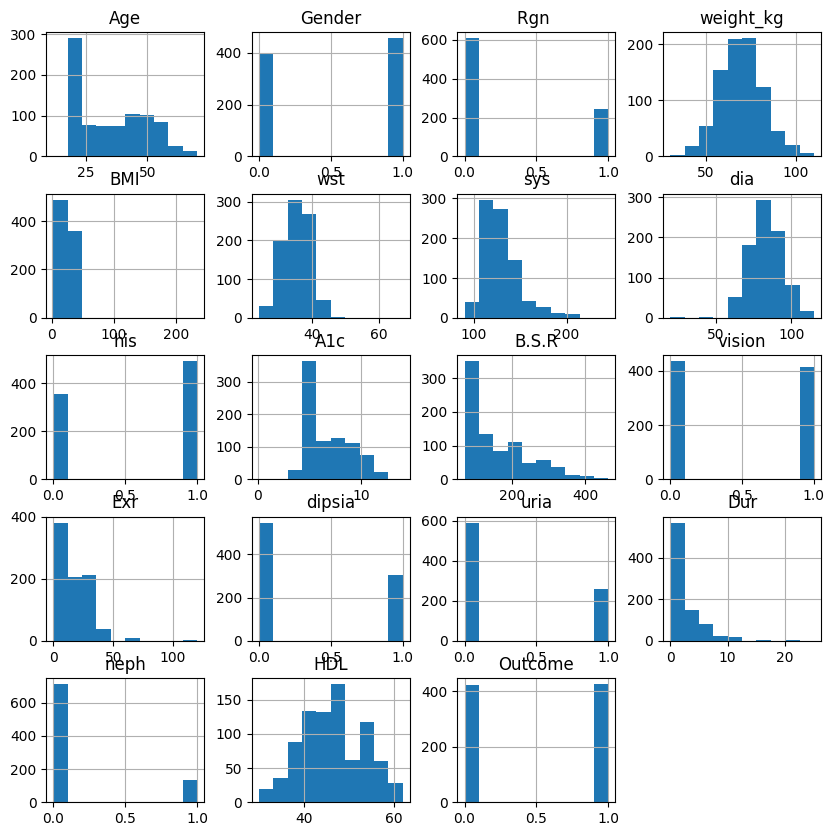

In [ ]:
data.hist(figsize=(10, 10))

# **Data Slicing**

---



In [ ]:
data_sample = data.drop(columns = ["Gender",	"Rgn ", "his", "vision", "dipsia",	"uria", "neph", "Outcome"])
data = data[["Gender",	"Rgn ", "his", "vision", "dipsia",	"uria", "neph", "Outcome"]]

In [ ]:
print(data_sample)

      Age  weight_kg    BMI   wst  sys  dia   A1c  B.S.R  Exr   Dur  HDL
0    60.0       76.0  29.90  41.0  130   90  8.90    278   30   5.0   60
1    57.0       64.0  24.30  39.0  120   80  8.50    165   20  20.0   42
2    56.0       70.0  25.80  43.0  125   90  8.30    139   40   5.0   53
3    45.0       79.0  30.20  39.0  125   85  9.30    238   10  10.0   59
4    50.0       74.0  28.00  38.0  150   90  8.45    374   20   4.0   53
..    ...        ...    ...   ...  ...  ...   ...    ...  ...   ...  ...
845  18.0       74.0  22.12  32.0  184   90  4.90     85   45   0.0   46
846  22.0       54.0  17.08  40.0  143   85  5.00    165   15   0.0   54
847  32.0       52.0  18.50  28.0  138   95  4.70     87    0   0.0   54
848  18.0       53.0  20.05  33.0  195   93  4.70     74   15   0.0   46
849  23.0       60.0  20.56  31.0  124   73  4.00     87    0   0.0   44

[850 rows x 11 columns]


In [ ]:
print(data)

     Gender  Rgn   his  vision  dipsia  uria  neph  Outcome
0         1     0    0       0       1     0     0        1
1         1     1    1       0       1     1     0        1
2         1     0    0       1       1     0     1        1
3         1     1    1       1       1     1     0        1
4         1     0    0       1       1     1     0        1
..      ...   ...  ...     ...     ...   ...   ...      ...
845       0     0    0       0       0     0     0        0
846       0     0    1       0       0     0     0        0
847       0     1    1       0       0     0     0        0
848       1     1    1       1       0     0     0        0
849       1     1    0       0       0     0     0        0

[850 rows x 8 columns]


# **Pair & Multi-Collinearity**

---



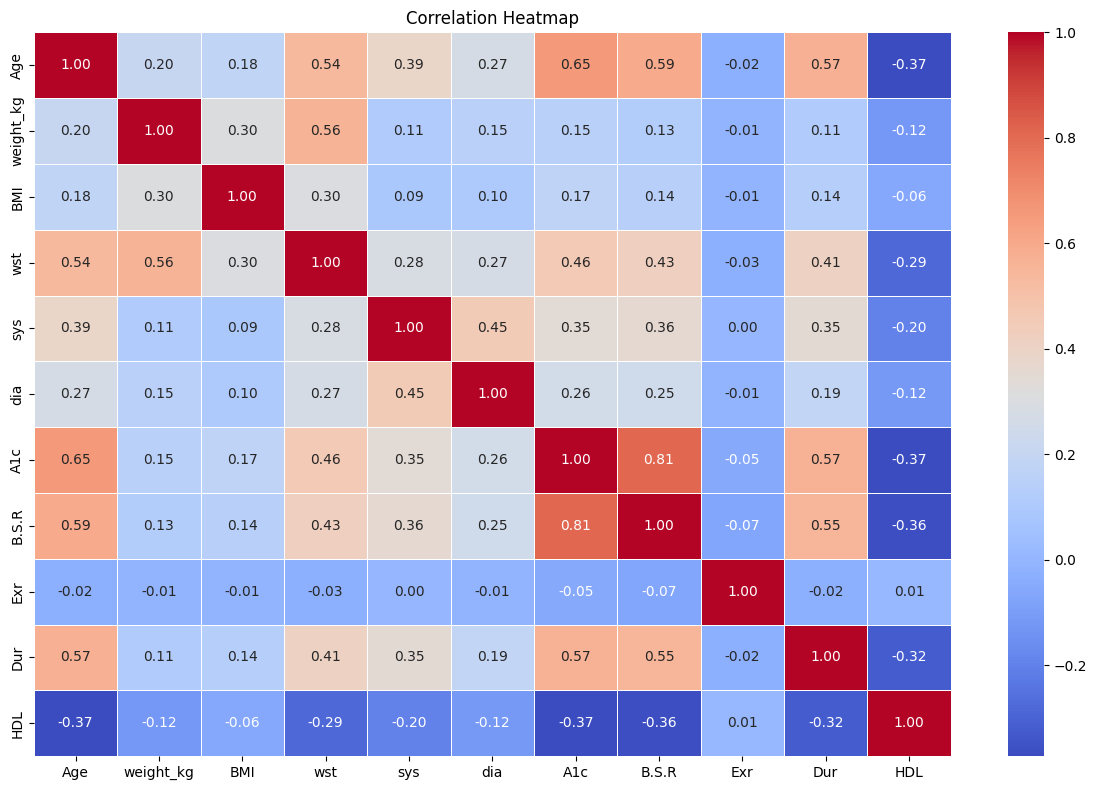

In [ ]:
correlation_matrix = data_sample.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
data_sample = data_sample.drop(["B.S.R"], axis = 1)

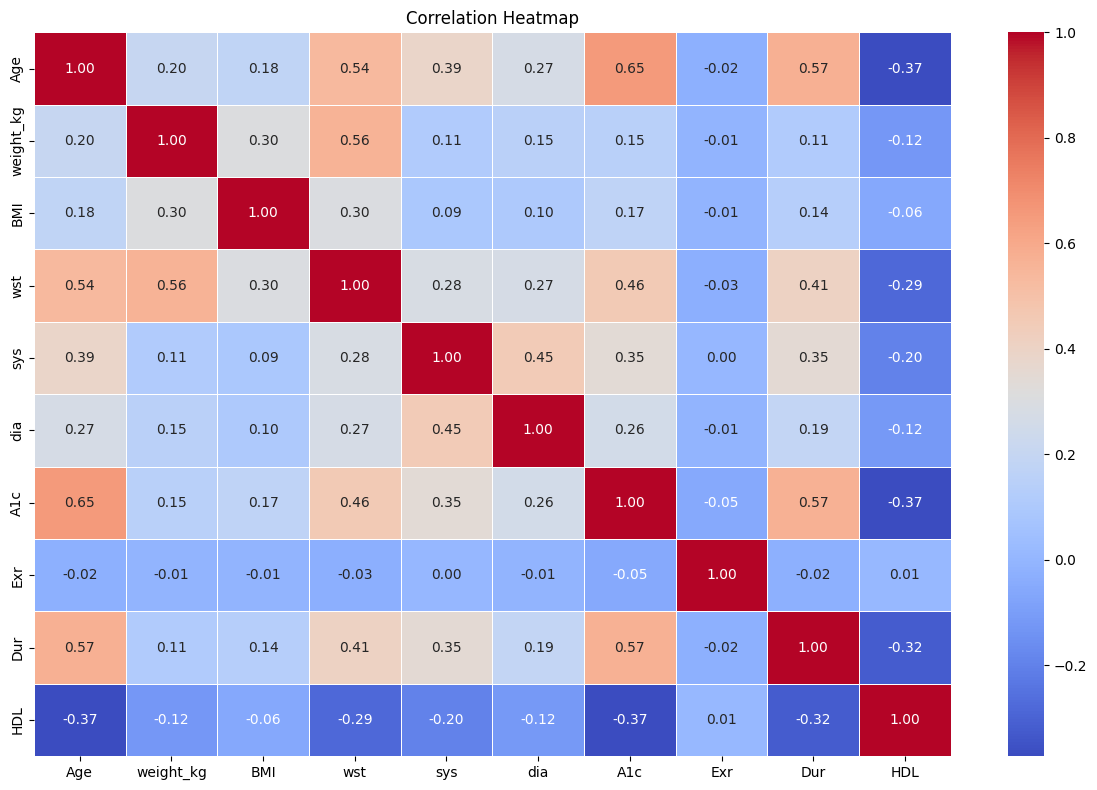

In [ ]:
correlation_matrix = data_sample.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# **Variance Inflation Factor**

---



In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
x_scaled = sc.fit_transform(data_sample)

vif_data = pd.DataFrame()
vif_data["feature"] = data_sample.columns
vif_data["VIF"] = [variance_inflation_factor(x_scaled, i) for i in range(x_scaled.shape[1])]
vif_data["Tolerance"] = 1 / vif_data["VIF"]

print(pd.DataFrame(vif_data))

     feature       VIF  Tolerance
0        Age  2.239950   0.446439
1  weight_kg  1.565645   0.638714
2        BMI  1.139934   0.877244
3        wst  2.171149   0.460586
4        sys  1.429654   0.699470
5        dia  1.303758   0.767013
6        A1c  2.038095   0.490654
7        Exr  1.003967   0.996049
8        Dur  1.724036   0.580034
9        HDL  1.219893   0.819744


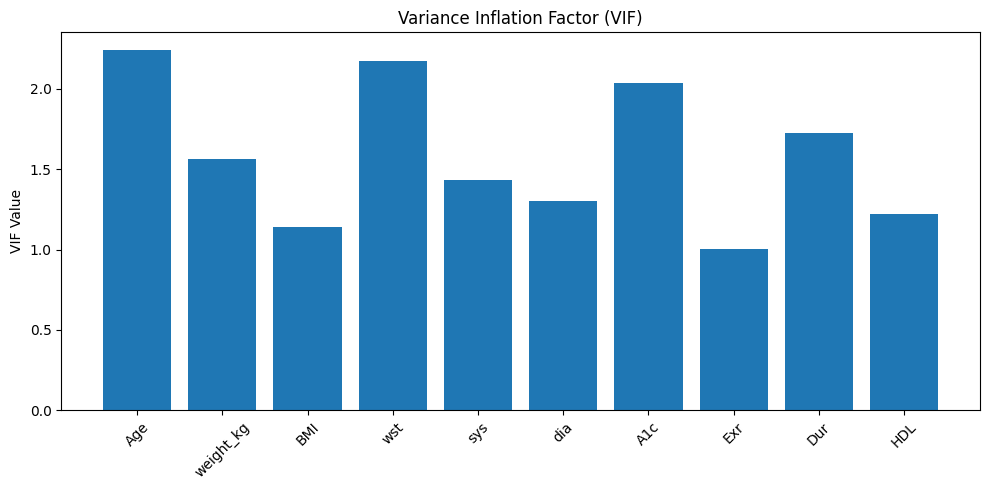

In [ ]:
vif = vif_data[vif_data["feature"] != "const"]

plt.figure(figsize=(10,5))
plt.bar(vif["feature"], vif["VIF"])
plt.ylabel("VIF Value")
plt.title("Variance Inflation Factor (VIF)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Box Plot**

---



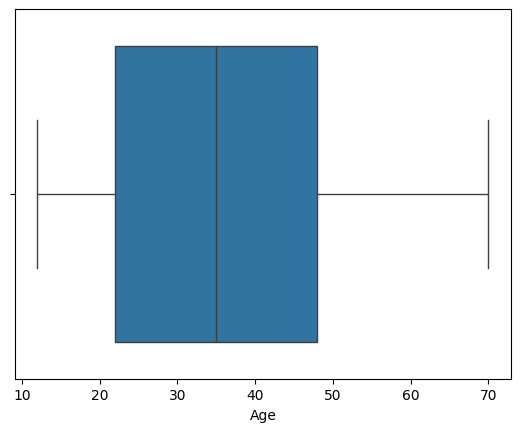

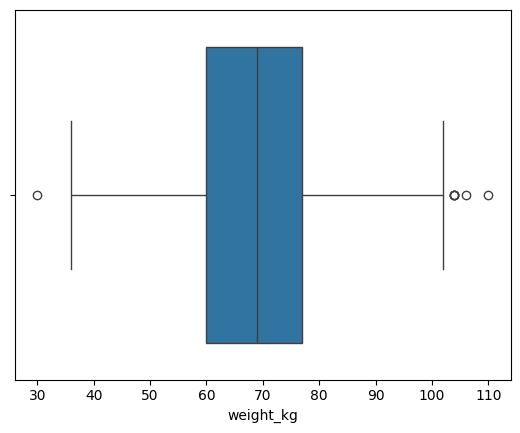

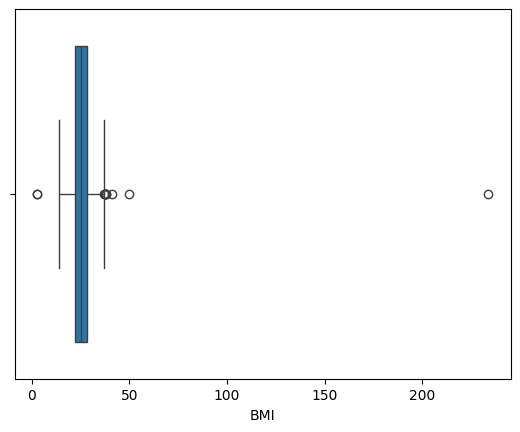

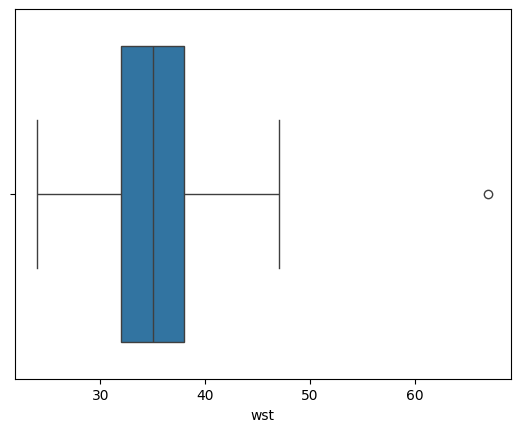

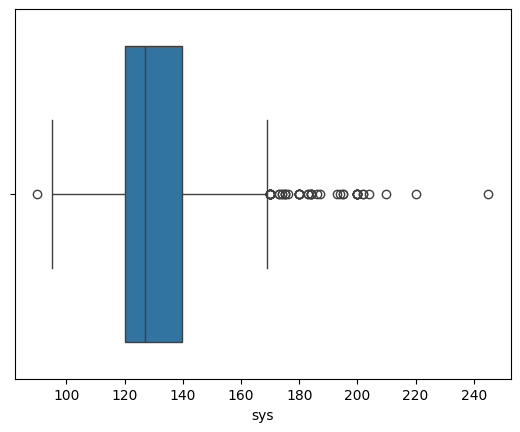

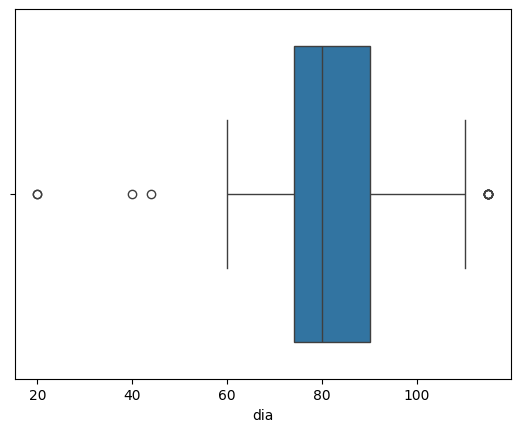

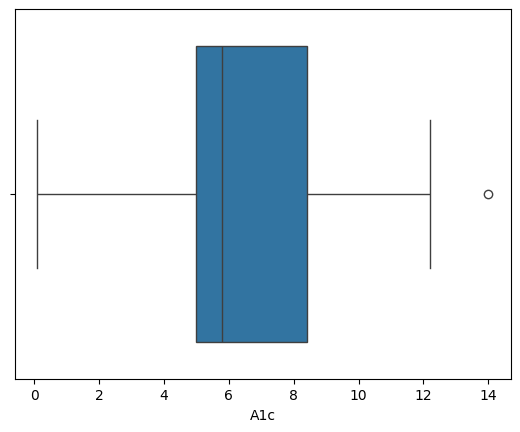

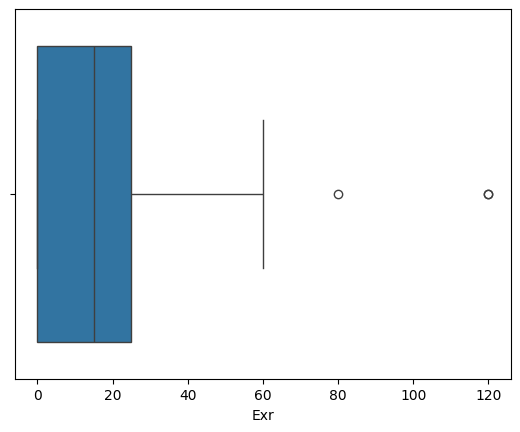

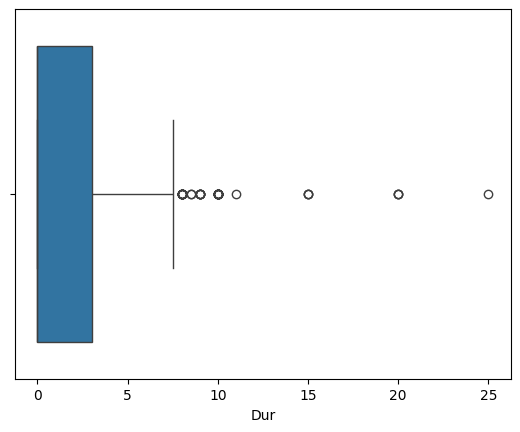

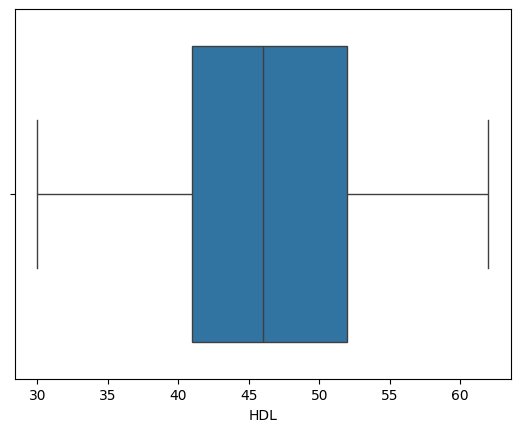

In [ ]:
for i in data_sample.select_dtypes(include = "number").columns:
  sns.boxplot(data = data_sample, x = i)
  plt.show()

# **Skewness**

---



In [ ]:
num_col = data_sample.select_dtypes(include = "number")

skewness = num_col.skew()

In [ ]:
def status(skewness):
  results = {}
  for col, skew in skewness.items():
    if skew > 1:
      category = "High Positive / Right Skew"

    elif skew < -1:
      category = "High Negative / Left Skew"

    elif -0.5 <= skew <= 0.5:
      category = "Approximately Normal"

    else:
      category = "Moderate Skew"

    results[col] = {"skewness": skew, "category": category}

  return pd.DataFrame(results).T

In [ ]:
print(status(skewness))

           skewness                    category
Age        0.370424        Approximately Normal
weight_kg  0.196096        Approximately Normal
BMI        17.43749  High Positive / Right Skew
wst        0.666387               Moderate Skew
sys        1.461654  High Positive / Right Skew
dia       -0.274157        Approximately Normal
A1c        0.699479               Moderate Skew
Exr        1.192895  High Positive / Right Skew
Dur        2.433313  High Positive / Right Skew
HDL        0.101976        Approximately Normal


# **Feature Scaling**

---



In [ ]:
col = data_sample.columns

In [ ]:
data = pd.concat((pd.DataFrame(x_scaled, columns = col), data), axis = 1)

In [ ]:
data

,Age,weight_kg,BMI,wst,sys,dia,A1c,Exr,Dur,HDL,Gender,Rgn,his,vision,dipsia,uria,neph,Outcome
0,1.771448,0.564832,0.519135,1.438425,-0.018635,0.652571,0.988875,0.968945,1.008443,2.050411,1,0,0,0,1,0,0,1
1,1.552023,-0.416497,-0.140999,0.931044,-0.521482,-0.198696,0.805009,0.328507,6.058581,-0.614949,1,1,1,0,1,1,0,1
2,1.478881,0.074167,0.035823,1.945805,-0.270059,0.652571,0.713076,1.609383,1.008443,1.013882,1,0,0,1,1,0,1,1
3,0.674323,0.810164,0.554499,0.931044,-0.270059,0.226938,1.172742,-0.311931,2.691822,1.902335,1,1,1,1,1,1,0,1
4,1.040031,0.401277,0.295161,0.677353,0.987060,0.652571,0.782026,0.328507,0.671767,1.013882,1,0,0,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
845,-1.300502,0.401277,-0.397980,-0.844789,2.696741,0.652571,-0.849786,1.929602,-0.674936,-0.022647,0,0,0,0,0,0,0,0
846,-1.007935,-1.234271,-0.992100,1.184734,0.635067,0.226938,-0.803820,0.008288,-0.674936,1.161957,0,0,1,0,0,0,0,0
847,-0.276519,-1.397826,-0.824709,-1.859551,0.383643,1.078205,-0.941719,-0.952369,-0.674936,1.161957,0,1,1,0,0,0,0,0
848,-1.300502,-1.316049,-0.641993,-0.591099,3.249874,0.907951,-0.941719,0.008288,-0.674936,-0.022647,1,1,1,1,0,0,0,0


# **Feature & Outcome**

---



In [ ]:
Y = data["Outcome"]
X = data.drop(columns = ["Outcome"])

In [ ]:
print("X: ", X.shape)
print("Y: ", Y.shape)

X:  (912, 18)
Y:  (912,)


# **Data Splitting**

---



In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=21)
X_valid, X_test, Y_valid, Y_test = train_test_split(X_test, Y_test, test_size=0.5, random_state=21)

In [ ]:
print("X_Train: ", X_train.shape)
print("Y_Train: ", Y_train.shape)
print("X_Valid: ", X_valid.shape)
print("Y_Valid: ", Y_valid.shape)
print("X_Test: ", X_test.shape)
print("Y_Test: ", Y_test.shape)

X_Train:  (595, 17)
Y_Train:  (595,)
X_Valid:  (127, 17)
Y_Valid:  (127,)
X_Test:  (128, 17)
Y_Test:  (128,)


# **Accuracy & Loss Arrays**

---



In [ ]:
train_losses = []
valid_losses = []
train_accuracies = []
valid_accuracies = []

# **Plot Accuracy & Loss Curves**

---



In [ ]:
def plot_loss_curve(train_losses, valid_losses, train_accuracies, valid_accuracies):

    # ---- dynamic loss scaling ----
    all_losses = train_losses + valid_losses
    loss_min = min(all_losses)
    loss_max = max(all_losses)
    padding = (loss_max - loss_min) * 0.4 if loss_max > loss_min else 0.5
    loss_lower = max(0, loss_min - padding)
    loss_upper = loss_max + padding

    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label="Train Loss", marker='o')
    plt.plot(valid_losses, label="Validation Loss", marker='o')
    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.title("Loss Curve")
    plt.ylim(loss_lower, loss_upper)
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---- accuracy scaling ----
    # Detect whether accuracy is in 0–1 or 0–100
    acc_max = max(train_accuracies + valid_accuracies)

    if acc_max <= 1:
        # accuracy is fractional -> use 0.5 to 1.0
        acc_lower, acc_upper = 0.5, 1.0
    else:
        # accuracy is percentage -> use 50 to 100
        acc_lower, acc_upper = 50, 100

    plt.figure(figsize=(10, 5))
    plt.plot(train_accuracies, label="Train Accuracy", marker='o')
    plt.plot(valid_accuracies, label="Validation Accuracy", marker='o')
    plt.xlabel("Iterations")
    plt.ylabel("Accuracy")
    plt.title("Accuracy Curve")
    plt.ylim(acc_lower, acc_upper)
    plt.legend()
    plt.grid(True)
    plt.show()


# **Confusion Matrix Plot**

---



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

def confusion_matrix_plot(best_model, X_test, Y_test):
  y_pred_test = best_model.predict(X_test)

  cm = confusion_matrix(Y_test, y_pred_test)

  plt.figure(figsize=(8, 6))
  sns.heatmap(cm, annot=True, fmt = 'd', cmap = 'Blues')
  plt.xlabel('Predicted Labels')
  plt.ylabel('True Labels')
  plt.title('Confusion Matrix')
  plt.show()


# **Classification Report**

---



In [ ]:
def validation(model, data, true):
  val_pred = model.predict(data)

  print("Model")
  print(classification_report(true, val_pred, digits=4))

# **Precision Recall Curve**

---



In [ ]:
def recall_precision_curve(Y_test, y_pred_test):
  from sklearn.metrics import precision_recall_curve
  precision, recall, _ = precision_recall_curve(Y_test, y_pred_test)

  plt.figure(figsize=(6,4))
  plt.plot(recall, precision)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title("Precision–Recall Curve")
  plt.show()

# **AUC Curve Plot**

---



In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
def auc_curve(Y_test, y_pred_test):
  fpr, tpr, thresholds = roc_curve(Y_test, y_pred_test)
  auc = roc_auc_score(Y_test, y_pred_test)

  plt.figure(figsize=(8, 6))
  plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
  plt.plot([0, 1], [0, 1], 'k--')
  plt.legend()
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('AUC Curve')
  plt.show()

# **Random Forest**

---



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss, accuracy_score, classification_report, confusion_matrix, roc_curve, auc


In [ ]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced'],
    'random_state': [21]
}

train_losses, valid_losses = [], []
train_accuracies, valid_accuracies = [], []
loss_gaps = []

best_valid_acc = 0
smallest_loss_gap = float("inf")
best_model = None
best_params = None

for n in param_grid['n_estimators']:
    for depth in param_grid['max_depth']:
        for min_split in param_grid['min_samples_split']:
            for min_leaf in param_grid['min_samples_leaf']:
                for max_feat in param_grid['max_features']:
                    for bootstrap in param_grid['bootstrap']:
                        for criterion in param_grid['criterion']:
                            for class_weight in param_grid['class_weight']:
                                model = RandomForestClassifier(
                                    n_estimators=n,
                                    max_depth=depth,
                                    min_samples_split=min_split,
                                    min_samples_leaf=min_leaf,
                                    max_features=max_feat,
                                    bootstrap=bootstrap,
                                    criterion=criterion,
                                    class_weight=class_weight,
                                    random_state=21
                                )
                                model.fit(X_train, Y_train)

                                y_train_prob = model.predict_proba(X_train)[:, 1]
                                y_valid_prob = model.predict_proba(X_valid)[:, 1]

                                train_loss = log_loss(Y_train, y_train_prob)
                                valid_loss = log_loss(Y_valid, y_valid_prob)

                                train_acc = accuracy_score(Y_train, model.predict(X_train))
                                valid_acc = accuracy_score(Y_valid, model.predict(X_valid))

                                loss_gap = abs(train_loss - valid_loss)

                                train_losses.append(train_loss)
                                valid_losses.append(valid_loss)
                                train_accuracies.append(train_acc)
                                valid_accuracies.append(valid_acc)
                                loss_gaps.append(loss_gap)

                                if valid_acc > best_valid_acc and loss_gap < smallest_loss_gap:
                                    best_valid_acc = valid_acc
                                    smallest_loss_gap = loss_gap
                                    best_params = (n, depth, min_split, min_leaf, max_feat, bootstrap, criterion, class_weight)
                                    best_model = model

print(f"\nBest Parameters Found: {best_params}")
print(f"Best Validation Accuracy: {round(best_valid_acc, 3)}")
print(f"Smallest Loss Gap (Train vs Validation): {round(smallest_loss_gap, 5)}")



Best Parameters Found: (50, 5, 2, 1, 'sqrt', True, 'gini', None)
Best Validation Accuracy: 0.992
Smallest Loss Gap (Train vs Validation): 0.0188


# **Accuracy and Loss Curves Random Forest**

---



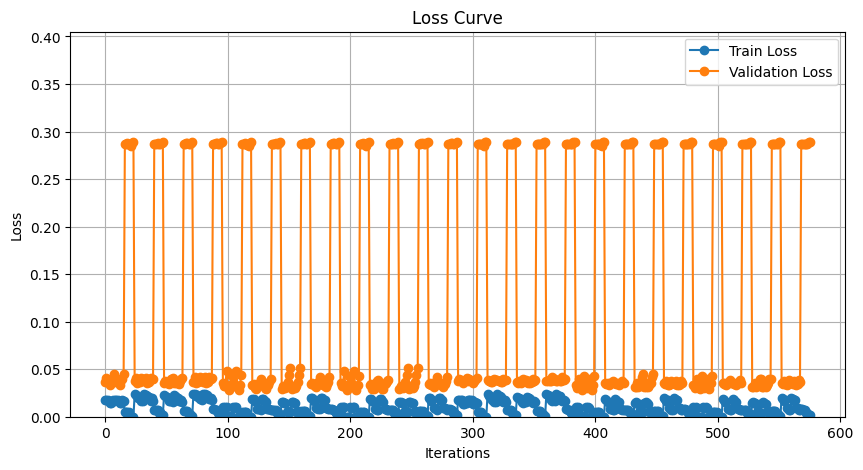

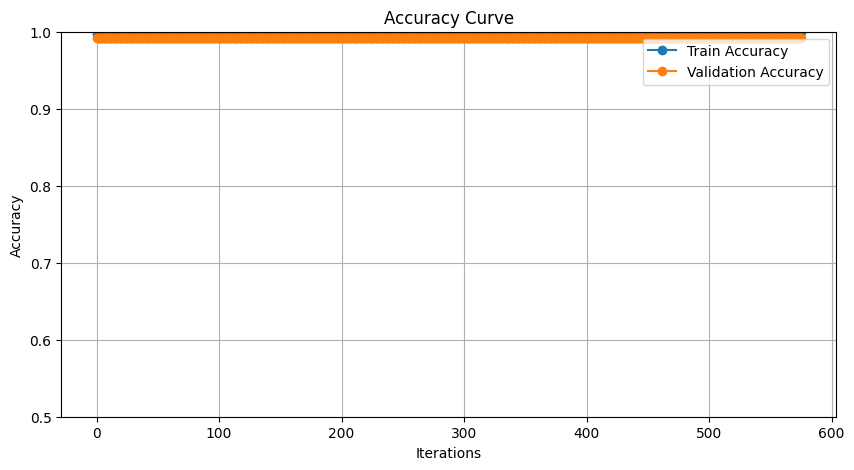

In [ ]:
plot_loss_curve(train_losses, valid_losses, train_accuracies, valid_accuracies)

In [ ]:
y_pred_train = best_model.predict(X_train)
y_pred_valid = best_model.predict(X_valid)
y_pred_test = best_model.predict(X_test)

In [ ]:
print("Train Accuracy: ", accuracy_score(Y_train, y_pred_train))
print("Valid Accuracy: ", accuracy_score(Y_valid, y_pred_valid))
print("Test Accuracy: ", accuracy_score(Y_test, y_pred_test))

print("Train Losses: ", log_loss(Y_train, y_pred_train))
print("Valid Losses: ", log_loss(Y_valid, y_pred_valid))
print("Test Losses: ", log_loss(Y_test, y_pred_test))

Train Accuracy:  0.9966386554621849
Valid Accuracy:  0.9921259842519685
Test Accuracy:  1.0
Train Losses:  0.12115513744241081
Valid Losses:  0.28380829440249744
Test Losses:  2.2204460492503136e-16


# **Confusion Matrices**

---



Training


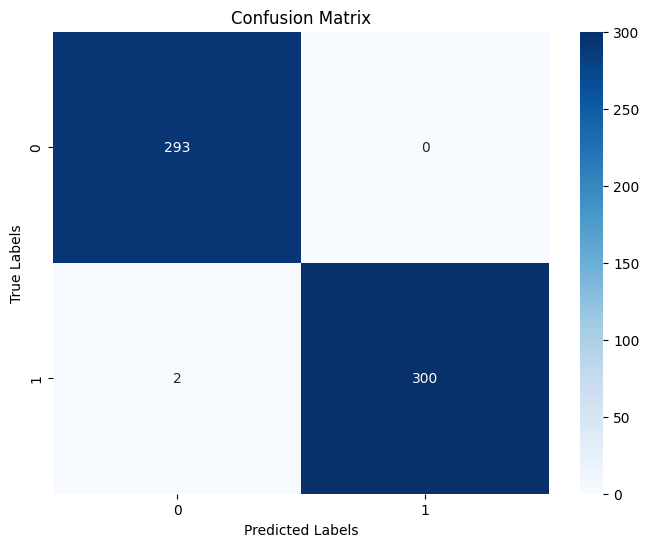


Validation


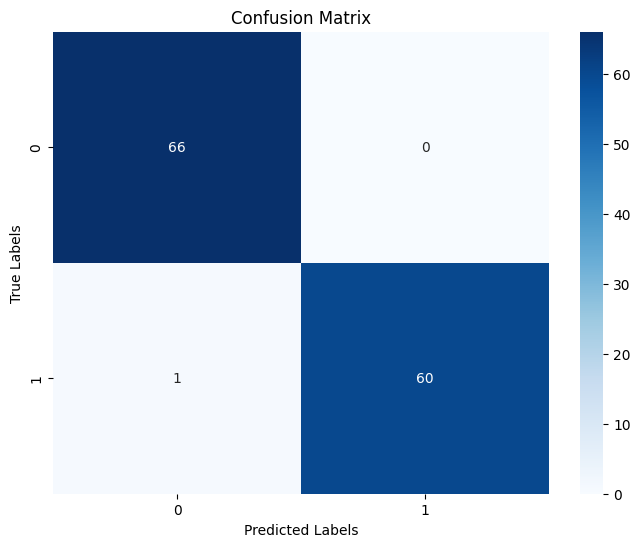


Testing


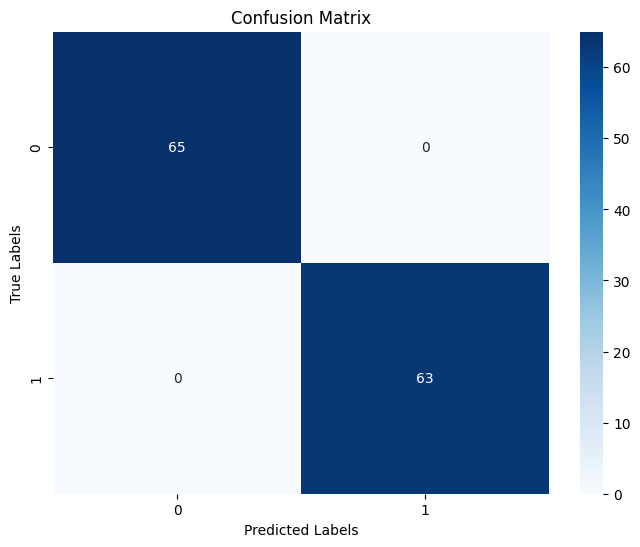

In [ ]:
print("Training")
confusion_matrix_plot(best_model, X_train, Y_train)
print()
print("Validation")
confusion_matrix_plot(best_model, X_valid, Y_valid)
print()
print("Testing")
confusion_matrix_plot(best_model, X_test, Y_test)

# **Classification Reports**

---



In [ ]:
print("Training")
validation(best_model, X_train, Y_train)
print()
print("Validation")
validation(best_model, X_valid, Y_valid)
print()
print("Testing")
validation(best_model, X_test, Y_test)

Training
Model
              precision    recall  f1-score   support

           0     0.9932    1.0000    0.9966       293
           1     1.0000    0.9934    0.9967       302

    accuracy                         0.9966       595
   macro avg     0.9966    0.9967    0.9966       595
weighted avg     0.9967    0.9966    0.9966       595


Validation
Model
              precision    recall  f1-score   support

           0     0.9851    1.0000    0.9925        66
           1     1.0000    0.9836    0.9917        61

    accuracy                         0.9921       127
   macro avg     0.9925    0.9918    0.9921       127
weighted avg     0.9922    0.9921    0.9921       127


Testing
Model
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        65
           1     1.0000    1.0000    1.0000        63

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000   

# **AUC & Precision Curves**

---



Train


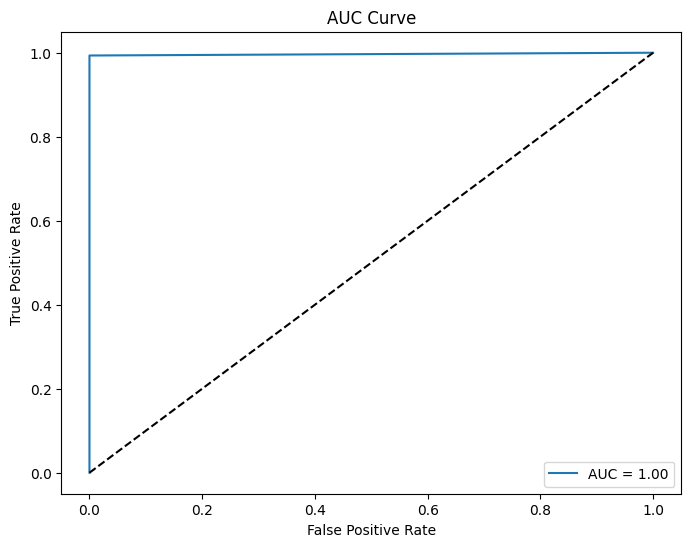

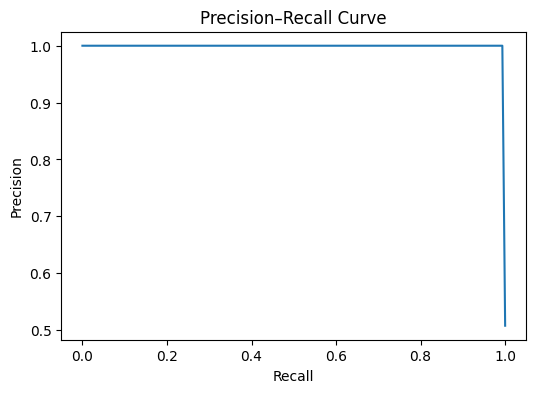


Valid


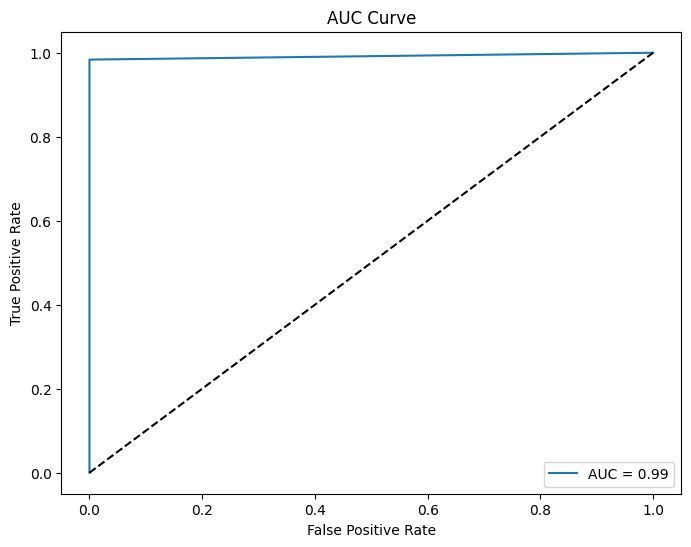

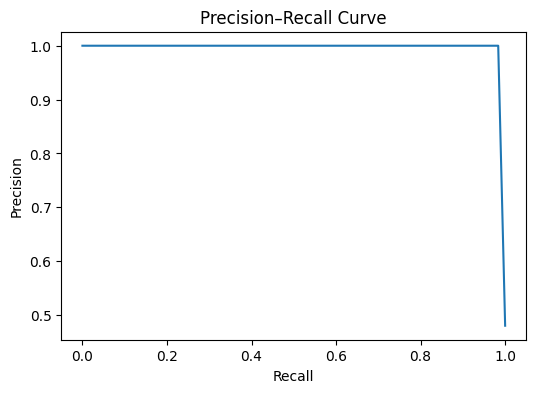


Test


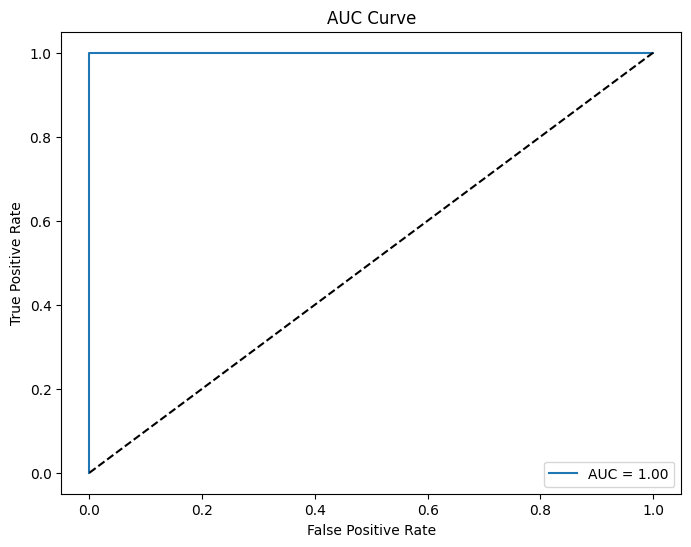

In [ ]:
print("Train")
auc_curve(Y_train, y_pred_train)
recall_precision_curve(Y_train, y_pred_train)
print()
print("Valid")
auc_curve(Y_valid, y_pred_valid)
recall_precision_curve(Y_valid, y_pred_valid)
print()
print("Test")
auc_curve(Y_test, y_pred_test)


# **Shap Explainer**

---



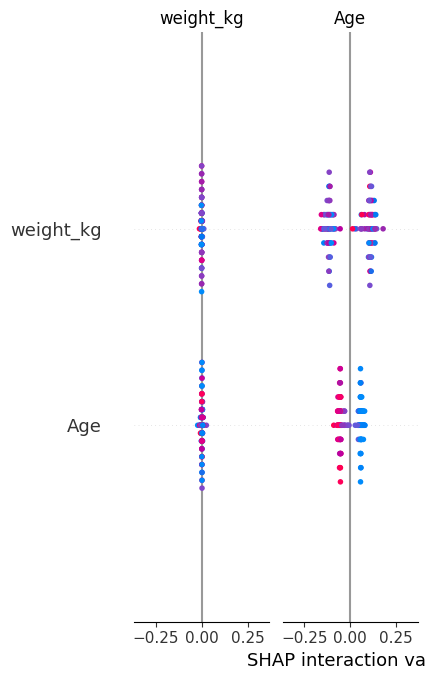

In [ ]:
import shap
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

# **Support Vector Machines**

---



In [ ]:
from sklearn.svm import SVC

In [ ]:
param_grid = {
    'kernel': ['linear', 'rbf', 'poly'],
    'C': [0.1, 1, 10],
    'degree': [2, 3],
    'gamma': ['scale', 'auto']
}

train_losses, valid_losses = [], []
train_accuracies, valid_accuracies = [], []

best_valid_acc = 0
best_params = None
best_model = None

for kernel in param_grid['kernel']:
    for C in param_grid['C']:
        for gamma in param_grid['gamma']:
            for degree in param_grid['degree']:

                if kernel == 'linear':
                    model = SVC(kernel=kernel, C=C, probability=True, random_state=21)
                elif kernel == 'rbf':
                    model = SVC(kernel=kernel, C=C, gamma=gamma, probability=True, random_state=21)
                else:
                    model = SVC(kernel=kernel, C=C, degree=degree, gamma=gamma, probability=True, random_state=21)

                model.fit(X_train, Y_train)

                y_train_prob = model.predict_proba(X_train)[:, 1]
                y_valid_prob = model.predict_proba(X_valid)[:, 1]

                train_loss = log_loss(Y_train, y_train_prob)
                valid_loss = log_loss(Y_valid, y_valid_prob)

                train_acc = accuracy_score(Y_train, model.predict(X_train))
                valid_acc = accuracy_score(Y_valid, model.predict(X_valid))

                train_losses.append(train_loss)
                valid_losses.append(valid_loss)
                train_accuracies.append(train_acc)
                valid_accuracies.append(valid_acc)

                if valid_acc > best_valid_acc:
                    best_valid_acc = valid_acc
                    best_params = (kernel, C, gamma, degree)
                    best_model = model

print(f"\nBest Parameters Found: {best_params}")
print(f"Best Validation Accuracy: {round(best_valid_acc, 3)}")



Best Parameters Found: ('linear', 1, 'scale', 2)
Best Validation Accuracy: 0.985


# **Accuracy & Loss Curves**

---



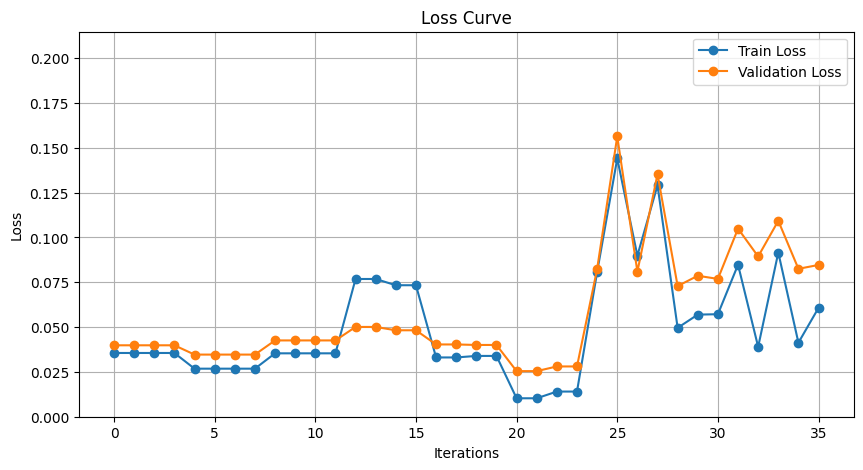

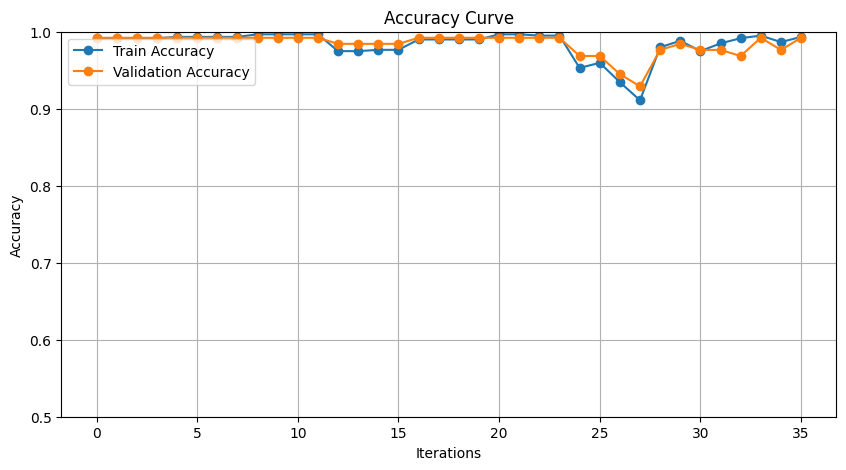

In [ ]:
plot_loss_curve(train_losses, valid_losses, train_accuracies, valid_accuracies)

In [ ]:
y_pred_train = best_model.predict(X_train)
y_pred_valid = best_model.predict(X_valid)
y_pred_test = best_model.predict(X_test)

In [ ]:
print("Train Accuracy: ", accuracy_score(Y_train, y_pred_train))
print("Valid Accuracy: ", accuracy_score(Y_valid, y_pred_valid))
print("Test Accuracy: ", accuracy_score(Y_test, y_pred_test))

print("Train Losses: ", log_loss(Y_train, y_pred_train))
print("Valid Losses: ", log_loss(Y_valid, y_pred_valid))
print("Test Losses: ", log_loss(Y_test, y_pred_test))

Train Accuracy:  0.9968652037617555
Valid Accuracy:  0.9854014598540146
Test Accuracy:  0.9927007299270073
Train Losses:  0.11298950905679381
Valid Losses:  0.5261847210090097
Test Losses:  0.26309236050450496


# **Confusion Matrix**

---



Training


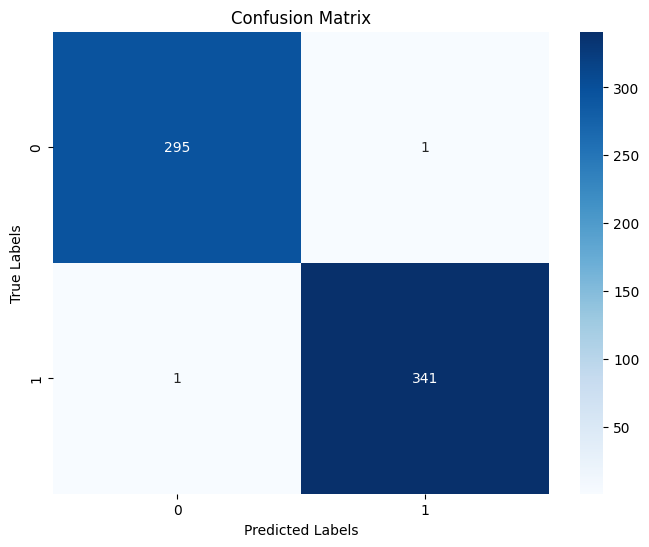


Validation


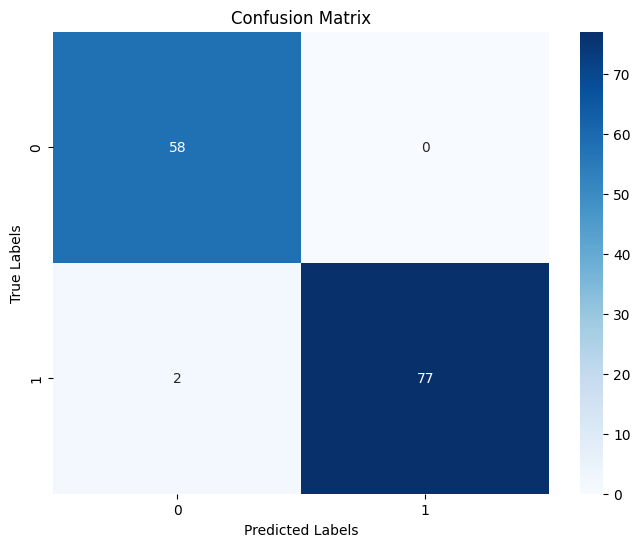


Testing


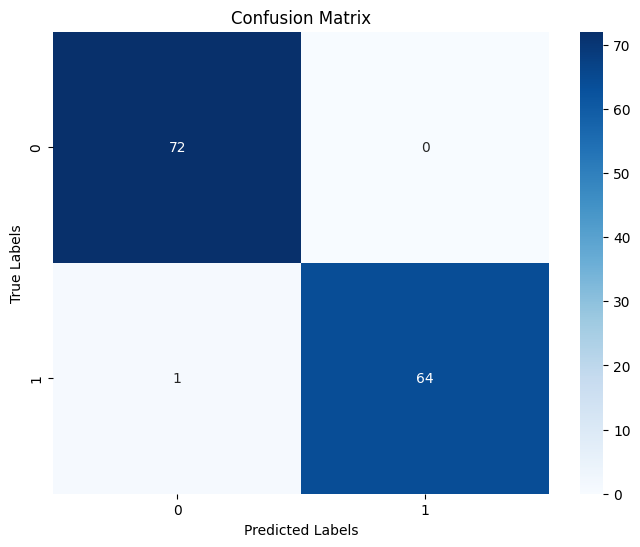

In [ ]:
print("Training")
confusion_matrix_plot(best_model, X_train, Y_train)
print()
print("Validation")
confusion_matrix_plot(best_model, X_valid, Y_valid)
print()
print("Testing")
confusion_matrix_plot(best_model, X_test, Y_test)

# **Classification Report**

---



In [ ]:
print("Training")
validation(best_model, X_train, Y_train)
print()
print("Validation")
validation(best_model, X_valid, Y_valid)
print()
print("Testing")
validation(best_model, X_test, Y_test)

Training
Model
              precision    recall  f1-score   support

           0     0.9832    1.0000    0.9915       293
           1     1.0000    0.9834    0.9917       302

    accuracy                         0.9916       595
   macro avg     0.9916    0.9917    0.9916       595
weighted avg     0.9917    0.9916    0.9916       595


Validation
Model
              precision    recall  f1-score   support

           0     0.9851    1.0000    0.9925        66
           1     1.0000    0.9836    0.9917        61

    accuracy                         0.9921       127
   macro avg     0.9925    0.9918    0.9921       127
weighted avg     0.9922    0.9921    0.9921       127


Testing
Model
              precision    recall  f1-score   support

           0     1.0000    0.9846    0.9922        65
           1     0.9844    1.0000    0.9921        63

    accuracy                         0.9922       128
   macro avg     0.9922    0.9923    0.9922       128
weighted avg     0.9923   

# **AUC & Precision Curve**

---



Train


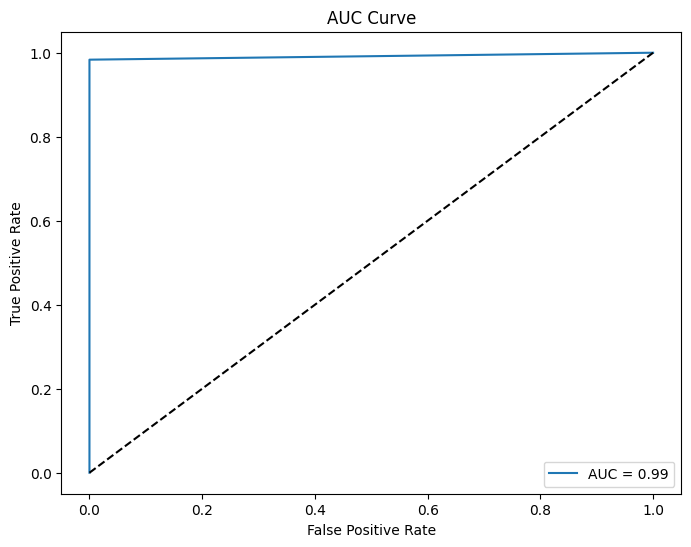

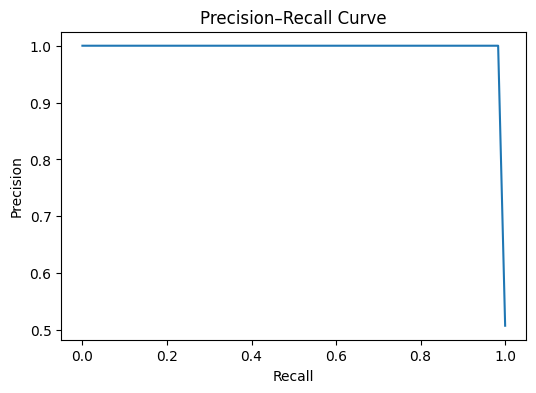


Valid


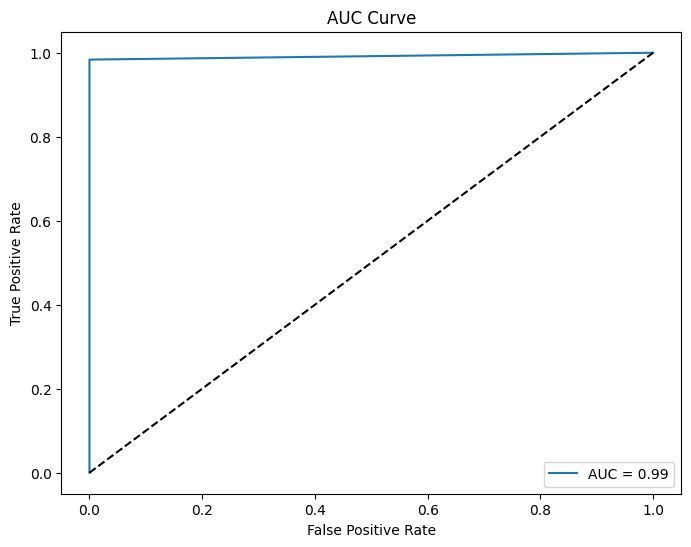

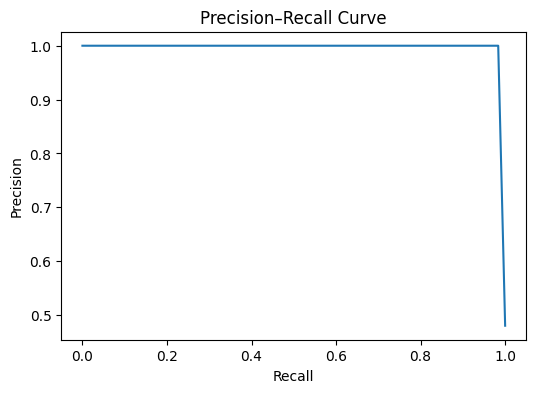


Test


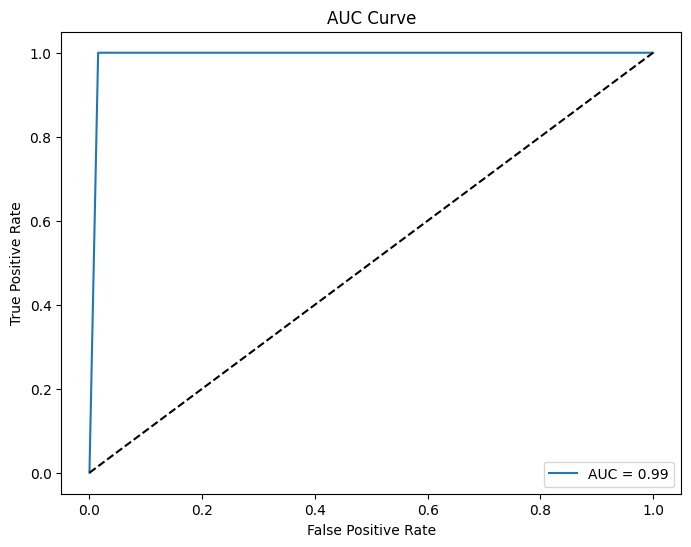

In [ ]:
print("Train")
auc_curve(Y_train, y_pred_train)
recall_precision_curve(Y_train, y_pred_train)
print()
print("Valid")
auc_curve(Y_valid, y_pred_valid)
recall_precision_curve(Y_valid, y_pred_valid)
print()
print("Test")
auc_curve(Y_test, y_pred_test)

# **Shap**

---



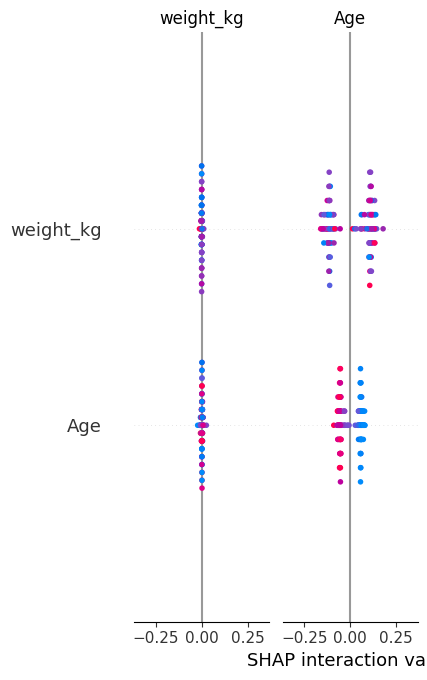

In [ ]:
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

# **XGBOOST**

---



In [ ]:
from xgboost import XGBClassifier

In [ ]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0]
}

train_losses, valid_losses = [], []
train_accuracies, valid_accuracies = [], []

best_valid_acc = 0
best_params = None
best_model = None

for n in param_grid['n_estimators']:
    for d in param_grid['max_depth']:
        for lr in param_grid['learning_rate']:
            for ss in param_grid['subsample']:
                model = XGBClassifier(n_estimators=n, max_depth=d, learning_rate=lr, subsample=ss, use_label_encoder=False, eval_metric='logloss', random_state=21)
                model.fit(X_train, Y_train)

                y_train_prob = model.predict_proba(X_train)[:, 1]
                y_valid_prob = model.predict_proba(X_valid)[:, 1]

                train_loss = log_loss(Y_train, y_train_prob)
                valid_loss = log_loss(Y_valid, y_valid_prob)

                train_acc = accuracy_score(Y_train, model.predict(X_train))
                valid_acc = accuracy_score(Y_valid, model.predict(X_valid))

                train_losses.append(train_loss)
                valid_losses.append(valid_loss)
                train_accuracies.append(train_acc)
                valid_accuracies.append(valid_acc)

                if valid_acc > best_valid_acc:
                    best_valid_acc = valid_acc
                    best_params = (n, d, lr, ss)
                    best_model = model

print(f"\nBest Parameters Found: {best_params}")
print(f"Best Validation Accuracy: {round(best_valid_acc, 3)}")


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [13:35:23] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [13:35:23] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [13:35:23] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [13:35:23] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [13:35:23] WARNING: /w


Best Parameters Found: (50, 3, 0.01, 0.8)
Best Validation Accuracy: 0.978


# **Accuracy & Loss Curves**

---



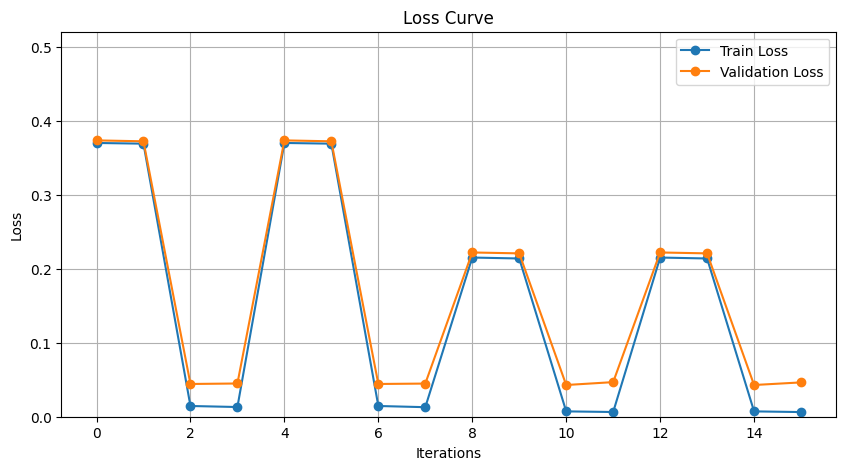

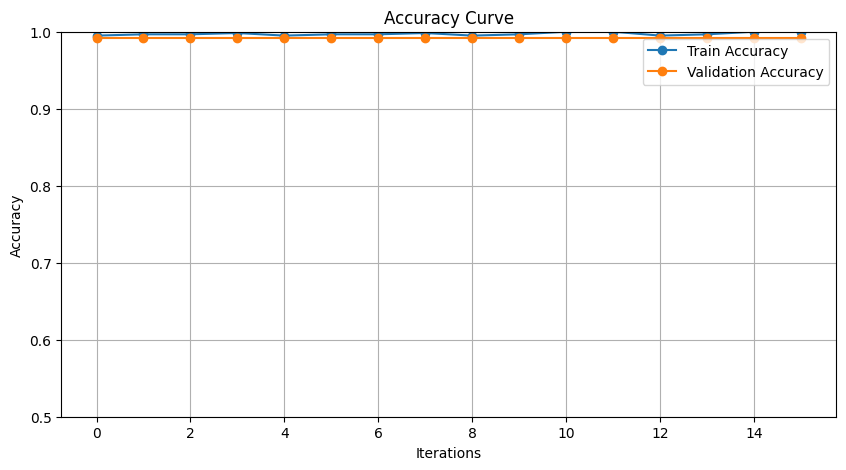

In [ ]:
plot_loss_curve(train_losses, valid_losses, train_accuracies, valid_accuracies)

In [ ]:
y_pred_train = best_model.predict(X_train)
y_pred_valid = best_model.predict(X_valid)
y_pred_test = best_model.predict(X_test)

In [ ]:
print("Train Accuracy: ", accuracy_score(Y_train, y_pred_train))
print("Valid Accuracy: ", accuracy_score(Y_valid, y_pred_valid))
print("Test Accuracy: ", accuracy_score(Y_test, y_pred_test))

print("Train Losses: ", log_loss(Y_train, y_pred_train))
print("Valid Losses: ", log_loss(Y_valid, y_pred_valid))
print("Test Losses: ", log_loss(Y_test, y_pred_test))

Train Accuracy:  0.9952978056426333
Valid Accuracy:  0.9781021897810219
Test Accuracy:  1.0
Train Losses:  0.1694842635851906
Valid Losses:  0.7892770815135145
Test Losses:  2.2204460492503136e-16


# **Confusion Matrix**

---



Training


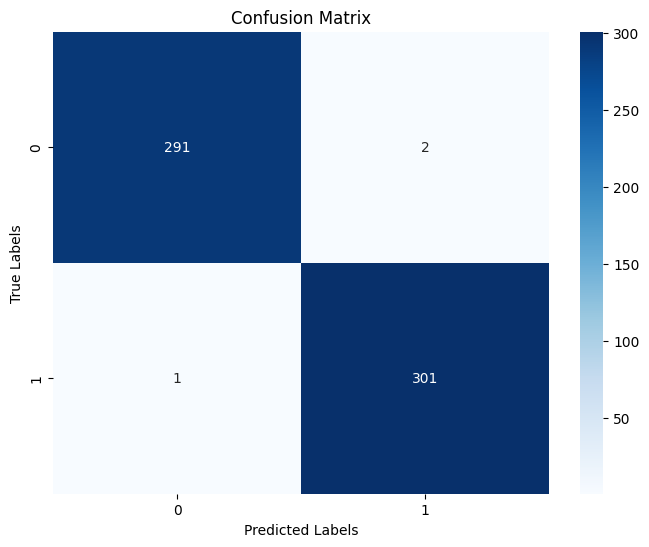


Validation


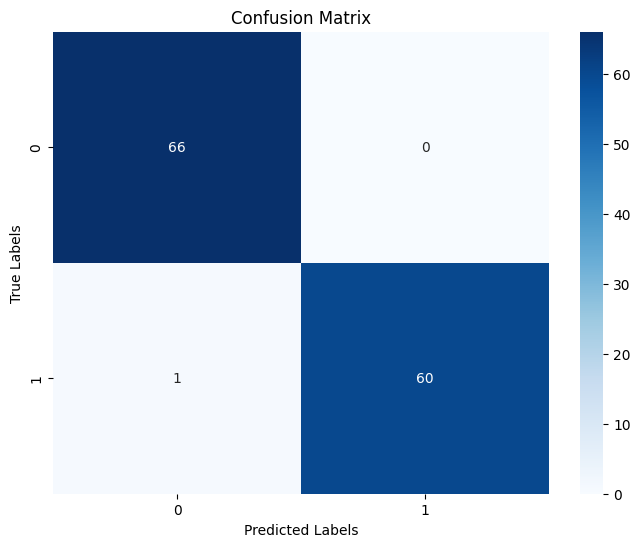


Testing


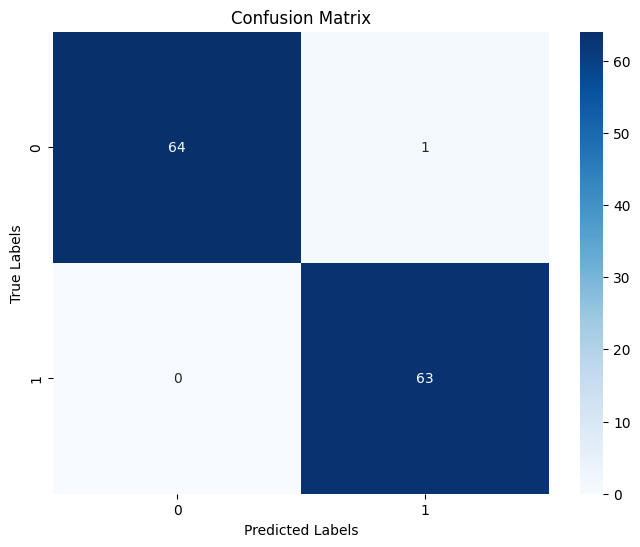

In [ ]:
print("Training")
confusion_matrix_plot(best_model, X_train, Y_train)
print()
print("Validation")
confusion_matrix_plot(best_model, X_valid, Y_valid)
print()
print("Testing")
confusion_matrix_plot(best_model, X_test, Y_test)

# **Classification Report**

---



In [ ]:
print("Training")
validation(best_model, X_train, Y_train)
print()
print("Validation")
validation(best_model, X_valid, Y_valid)
print()
print("Testing")
validation(best_model, X_test, Y_test)

Training
Model
              precision    recall  f1-score   support

           0     0.9966    0.9932    0.9949       296
           1     0.9942    0.9971    0.9956       342

    accuracy                         0.9953       638
   macro avg     0.9954    0.9952    0.9953       638
weighted avg     0.9953    0.9953    0.9953       638


Validation
Model
              precision    recall  f1-score   support

           0     0.9661    0.9828    0.9744        58
           1     0.9872    0.9747    0.9809        79

    accuracy                         0.9781       137
   macro avg     0.9766    0.9787    0.9776       137
weighted avg     0.9783    0.9781    0.9781       137


Testing
Model
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        72
           1     1.0000    1.0000    1.0000        65

    accuracy                         1.0000       137
   macro avg     1.0000    1.0000    1.0000       137
weighted avg     1.0000   

# **AUC & ROC Curves**

---



Train


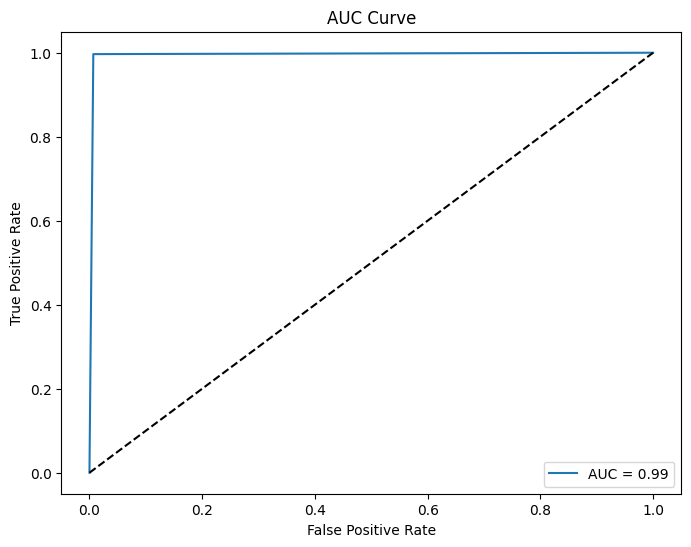

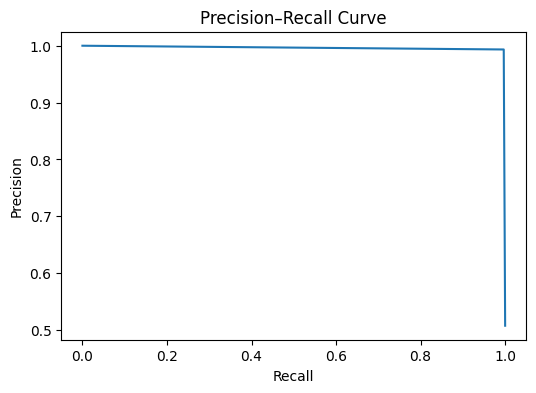


Valid


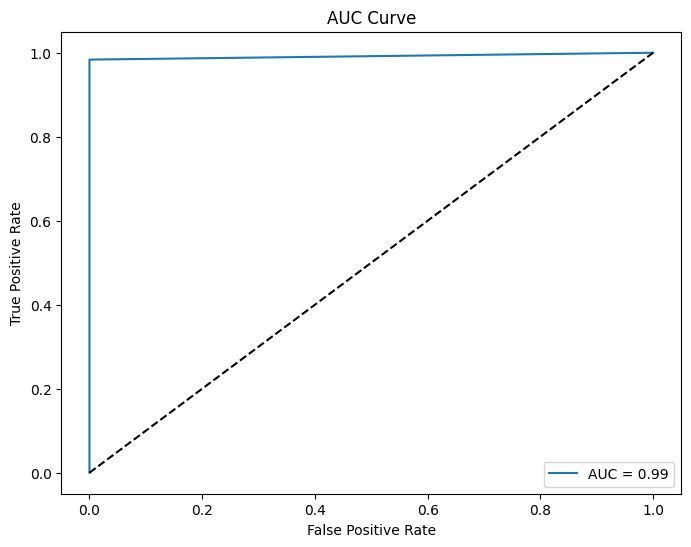

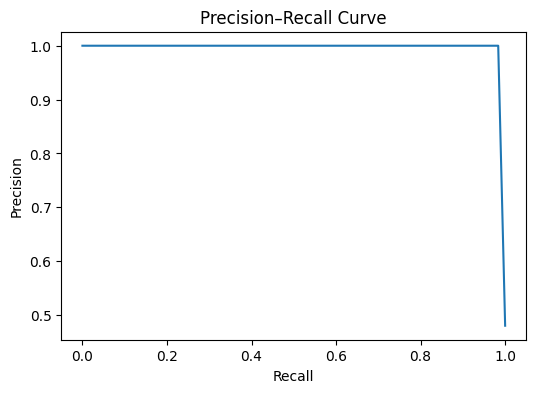


Test


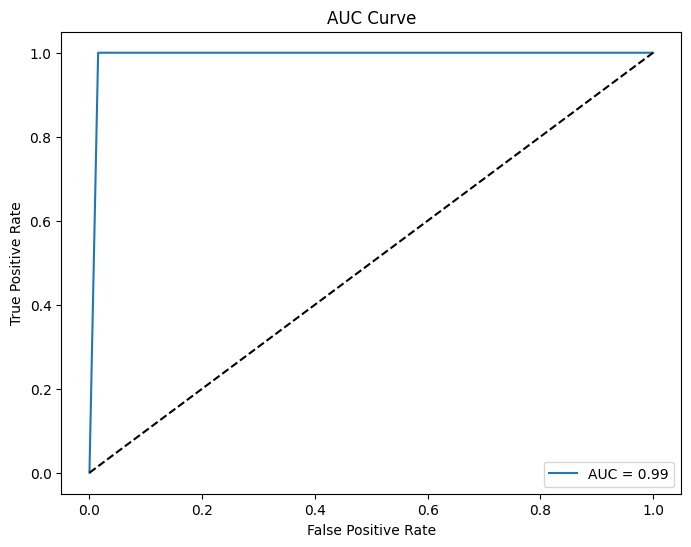

In [ ]:
print("Train")
auc_curve(Y_train, y_pred_train)
recall_precision_curve(Y_train, y_pred_train)
print()
print("Valid")
auc_curve(Y_valid, y_pred_valid)
recall_precision_curve(Y_valid, y_pred_valid)
print()
print("Test")
auc_curve(Y_test, y_pred_test)